# 9. Comparación de resultados

En este capítulo reunimos en una sola tabla el desempeño y el costo de todas las configuraciones (entorno, modelo y codificación), comparamos tiempos y memoria, y presentamos las ablaciones: dimensión del hashing, cruces de variables, profundidad del MLP y ponderación de clases.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

from src.metrics import paired_t
enc = R.runs("scikit-learn", "encoding")
best_enc = enc.groupby("encoding")["val.roc_auc"].mean().idxmax()
todo = pd.concat([enc, R.runs("scikit-learn", "baselines"), R.runs("PySpark", "main")], ignore_index=True)
todo["configuración"] = todo.apply(R.label, axis=1)
print(f"{len(todo)} corridas | mejor codificación del MLP en validación: {C.ENCODING_LABELS[best_enc]}")

Resultados: results | prueba de humo: False
42 corridas | mejor codificación del MLP en validación: Hashing 2^14


## 9.1 Tabla comparativa

Cada celda muestra media ± desviación estándar entre semillas y el intervalo de confianza del 95 % ($t$). Los tiempos y la memoria son medias entre semillas.

In [2]:
mets = ["test.roc_auc", "test.pr_auc", "test.log_loss", "test.ece"]
s = R.summarize(todo, ["env", "size", "configuración"], mets + ["bench.fit_s", "bench.predict_s", "bench.fit_peak_mb"])
t = R.pretty(s, ["env", "size", "configuración"], mets)
t["entrenamiento (s)"] = s["bench.fit_s|media"].round(1).values
t["predicción (s)"] = s["bench.predict_s|media"].round(1).values
t["memoria pico (MB)"] = s["bench.fit_peak_mb|media"].round(0).values
t = t.sort_values(["env", "size", "ROC AUC"], ascending=[False, True, False])
display(t.rename(columns={"env": "entorno", "size": "muestra"}).set_index(["entorno", "muestra", "configuración"]))
s.to_csv(C.SUMMARY / "tabla_9_1.csv", index=False)

semillas  \
entorno      muestra configuración                                  
scikit-learn 1M      MLP · Hashing 2^14                         5   
                     MLP · Hashing 2^16                         5   
                     MLP · Hashing 2^12                         5   
                     Regresión logística · Hashing 2^14         5   
                     MLP · Target encoding OOF                  5   
                     Gradient boosting · Frecuencia             5   
                     Regresión logística · Frecuencia           5   
                     MLP · Frecuencia                           5   
PySpark      100k    Regresión logística · Hashing 2^12         1   
                     MLP · Hashing 2^12                         1   

                                                                                  ROC AUC  \
entorno      muestra configuración                                                          
scikit-learn 1M      MLP · Hashing 2^14                  0.7315 ± 0.0014 [0.7297, 0.7333]   
                     MLP · Hashing 2^16                  0.7300 ± 0.0019 [0.7277, 0.7323]   
                     MLP · Hashing 2^12                  0.7293 ± 0.0020 [0.7268, 0.7317]   
                     Regresión logística · Hashing 2^14  0.7273 ± 0.0019 [0.7250, 0.7296]   
                     MLP · Target encoding OOF           0.7256 ± 0.0033 [0.7216, 0.7297]   
                     Gradient boosting · Frecuencia      0.7246 ± 0.0011 [0.7232, 0.7260]   
                     Regresión logística · Frecuencia    0.6777 ± 0.0024 [0.6747, 0.6807]   
                     MLP · Frecuencia                    0.6632 ± 0.0121 [0.6482, 0.6783]   
PySpark      100k    Regresión logística · Hashing 2^12                   0.7140 ± 0.0000   
                     MLP · Hashing 2^12                                   0.7109 ± 0.0000   

                                                                                   PR AUC  \
entorno      muestra configuración                                                          
scikit-learn 1M      MLP · Hashing 2^14                  0.3606 ± 0.0013 [0.3589, 0.3622]   
                     MLP · Hashing 2^16                  0.3590 ± 0.0030 [0.3552, 0.3628]   
                     MLP · Hashing 2^12                  0.3580 ± 0.0024 [0.3550, 0.3611]   
                     Regresión logística · Hashing 2^14  0.3518 ± 0.0017 [0.3496, 0.3539]   
                     MLP · Target encoding OOF           0.3541 ± 0.0031 [0.3503, 0.3580]   
                     Gradient boosting · Frecuencia      0.3500 ± 0.0011 [0.3487, 0.3513]   
                     Regresión logística · Frecuencia    0.2976 ± 0.0012 [0.2961, 0.2991]   
                     MLP · Frecuencia                    0.3036 ± 0.0115 [0.2893, 0.3179]   
PySpark      100k    Regresión logística · Hashing 2^12                   0.3276 ± 0.0000   
                     MLP · Hashing 2^12                                   0.3275 ± 0.0000   

                                                                                 Log loss  \
entorno      muestra configuración                                                          
scikit-learn 1M      MLP · Hashing 2^14                  0.4055 ± 0.0005 [0.4048, 0.4062]   
                     MLP · Hashing 2^16                  0.4070 ± 0.0020 [0.4046, 0.4094]   
                     MLP · Hashing 2^12                  0.4060 ± 0.0007 [0.4051, 0.4069]   
                     Regresión logística · Hashing 2^14  0.4084 ± 0.0019 [0.4060, 0.4107]   
                     MLP · Target encoding OOF           0.4084 ± 0.0016 [0.4064, 0.4104]   
                     Gradient boosting · Frecuencia      0.4085 ± 0.0005 [0.4079, 0.4091]   
                     Regresión logística · Frecuencia    0.4285 ± 0.0013 [0.4269, 0.4301]   
                     MLP · Frecuencia                    0.4320 ± 0.0042 [0.4268, 0.4373]   
PySpark      100k    Regresión logística · Hashing 2^12         

## 9.2 Tiempo, memoria y desempeño

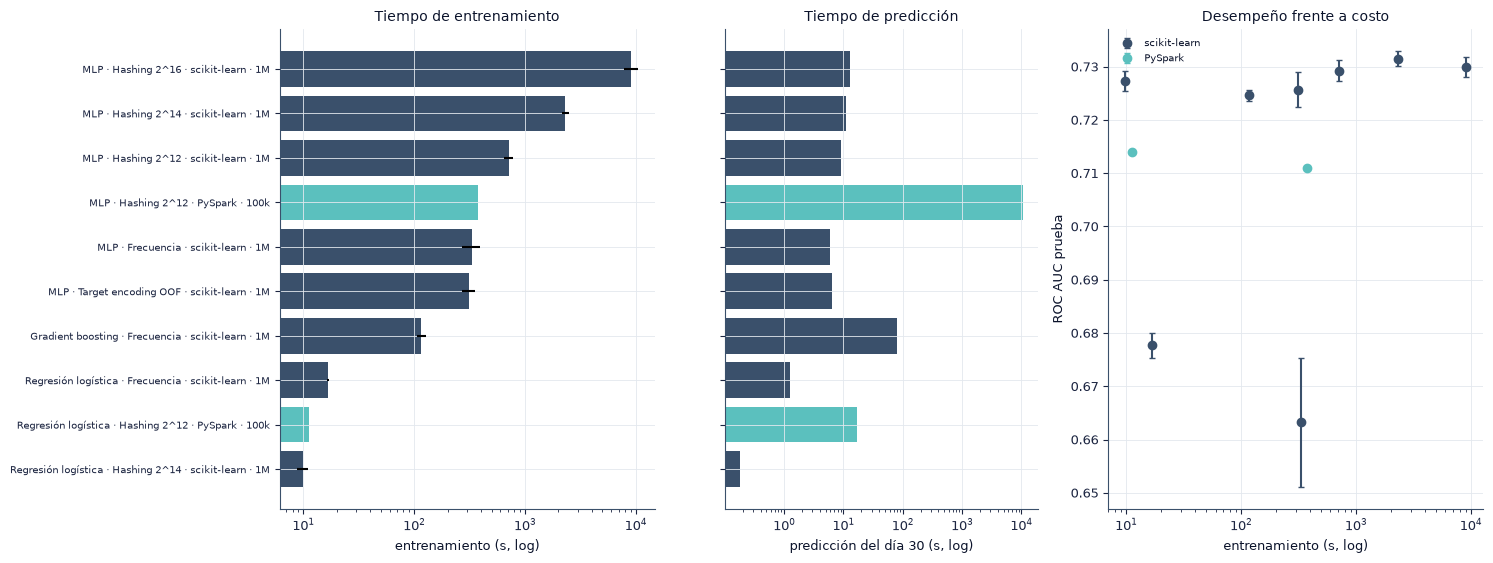

In [3]:
s["etiqueta"] = s["configuración"] + " · " + s["env"] + " · " + s["size"].astype(str)
ss = s.sort_values("bench.fit_s|media")
fig, axes = plt.subplots(1, 3, figsize=(15, 0.42 * len(ss) + 1.5), gridspec_kw={"width_ratios": [1.2, 1, 1.2]})
colr = [C.ENV_COLORS[e] for e in ss["env"]]
axes[0].barh(ss["etiqueta"], ss["bench.fit_s|media"], xerr=ss["bench.fit_s|de"], color=colr); axes[0].set_xscale("log")
axes[0].set_xlabel("entrenamiento (s, log)"); axes[0].set_title("Tiempo de entrenamiento"); axes[0].tick_params(axis="y", labelsize=7)
axes[1].barh(ss["etiqueta"], ss["bench.predict_s|media"], color=colr); axes[1].set_xscale("log"); axes[1].set_yticklabels([])
axes[1].set_xlabel("predicción del día 30 (s, log)"); axes[1].set_title("Tiempo de predicción")
for e in C.ENV_COLORS:
    g = s[s["env"] == e]
    axes[2].errorbar(g["bench.fit_s|media"], g["test.roc_auc|media"], yerr=g["test.roc_auc|de"], fmt="o", color=C.ENV_COLORS[e], label=e, capsize=2)
axes[2].set_xscale("log"); axes[2].set_xlabel("entrenamiento (s, log)"); axes[2].set_ylabel("ROC AUC prueba"); axes[2].set_title("Desempeño frente a costo"); axes[2].legend(fontsize=7)
fig.tight_layout(); P.save(fig, "9_2_tiempos_auc"); plt.show()

In [4]:
top = s.sort_values("test.roc_auc|media", ascending=False).iloc[0]
rap = s.sort_values("bench.fit_s|media").iloc[0]
cal = s.sort_values("test.ece|media").iloc[0]
R.findings(
    f"La configuración con mayor ROC AUC es {top['etiqueta']} ({top['test.roc_auc|media']:.4f}), con {R.secs(top['bench.fit_s|media'])} de entrenamiento. "
    f"La más rápida es {rap['etiqueta']} ({R.secs(rap['bench.fit_s|media'])}, AUC {rap['test.roc_auc|media']:.4f}) y la mejor calibrada "
    f"{cal['etiqueta']} (ECE {cal['test.ece|media']:.4f}).",
    {"Desempeño": f"las tres mejores configuraciones están dentro de {s['test.roc_auc|media'].nlargest(3).max() - s['test.roc_auc|media'].nlargest(3).min():.4f} de AUC; las pruebas del capítulo 6 indican qué diferencias son relevantes.",
     "Costo": "el tiempo de entrenamiento varía en varios órdenes de magnitud entre configuraciones, mucho más que el AUC.",
     "Riesgos": f"las configuraciones de Spark con {R.num(C.SIZES[C.SPARK_MLP_SIZE])} filas no son comparables en AUC con las de scikit-learn con {R.num(C.SIZES[C.MAIN_SIZE])}: el tamaño de la muestra también cambia."})

### Hallazgos y decisiones

La configuración con mayor ROC AUC es MLP · Hashing 2^14 · scikit-learn · 1M (0.7315), con 38.7 min de entrenamiento. La más rápida es Regresión logística · Hashing 2^14 · scikit-learn · 1M (9.8 s, AUC 0.7273) y la mejor calibrada MLP · Hashing 2^12 · scikit-learn · 1M (ECE 0.0097).

- **Desempeño:** las tres mejores configuraciones están dentro de 0.0022 de AUC; las pruebas del capítulo 6 indican qué diferencias son relevantes.
- **Costo:** el tiempo de entrenamiento varía en varios órdenes de magnitud entre configuraciones, mucho más que el AUC.
- **Riesgos:** las configuraciones de Spark con 100 000 filas no son comparables en AUC con las de scikit-learn con 1 000 000: el tamaño de la muestra también cambia.


## 9.3 Ablaciones

Cada ablación cambia un solo factor del MLP de referencia (codificación elegida en validación, hiperparámetros de Optuna, sin pesos y sin cruces) y mantiene las semillas. Reportamos la diferencia de ROC AUC pareada por semilla con su intervalo del 95 %.

| Ablación | Variante | Referencia |
|---|---|---|
| Dimensión del hashing | $2^{12}$ y $2^{16}$ | $2^{14}$ |
| Cruces de variables | Con `site_id × device_type` y `app_id × device_type` | Sin cruces, misma codificación |
| Profundidad del MLP | (100), (100, 50), (256, 128), (256, 128, 64) | Arquitectura de Optuna |
| Ponderación de clases | Pesos $N / (2 N_k)$ | Sin pesos |

ΔAUC  IC inf  IC sup       p  \
ablación              variante                                              
dimensión del hashing Hashing 2^12 − 2^14 -0.0022 -0.0048  0.0004  0.0760   
                      Hashing 2^16 − 2^14 -0.0015 -0.0053  0.0023  0.3411   

                                           semillas  \
ablación              variante                        
dimensión del hashing Hashing 2^12 − 2^14         5   
                      Hashing 2^16 − 2^14         5   

                                           relevante (|Δ| ≥ δ y p < 0.05)  
ablación              variante                                             
dimensión del hashing Hashing 2^12 − 2^14                           False  
                      Hashing 2^16 − 2^14                           False

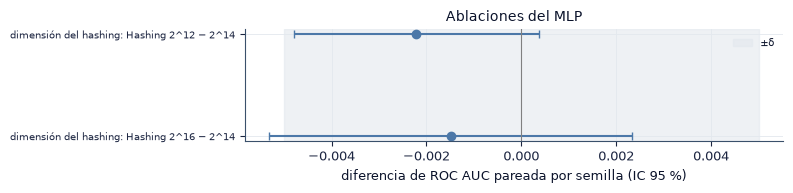

In [5]:
ref = enc[enc["encoding"] == best_enc].set_index("seed")
filas = []
def comparar(nombre, variante, df, base):
    a = df.set_index("seed")["test.roc_auc"]; b = base["test.roc_auc"]
    seeds = sorted(set(a.index) & set(b.index))
    if len(seeds) < 2:
        return
    t = paired_t(a.loc[seeds].values, b.loc[seeds].values)
    filas.append({"ablación": nombre, "variante": variante, "ΔAUC": t["diff"], "IC inf": t.get("lo"), "IC sup": t.get("hi"), "p": t["p"], "semillas": len(seeds)})

h14 = enc[enc["encoding"] == "hash_14"].set_index("seed")
for e in ["hash_12", "hash_16"]:
    comparar("dimensión del hashing", C.ENCODING_LABELS[e] + " − 2^14", enc[enc["encoding"] == e], h14)
cr = R.runs("scikit-learn", "ablation_cross")
if len(cr):
    e_cr = cr["encoding"].iat[0]
    comparar("cruces de variables", f"con cruces − sin cruces ({C.ENCODING_LABELS[e_cr]})", cr, enc[enc["encoding"] == e_cr].set_index("seed"))
dp = R.runs("scikit-learn", "ablation_depth")
opt_hl = load_json(C.COMMON / f"optuna_mlp_{C.MLP_TUNE_ENCODING}.json")["best_params"]["hidden_layer_sizes"]
for hl, g in dp.groupby(dp["params.hidden_layer_sizes"]):
    comparar("profundidad", f"({hl.replace('-', ', ')}) − ({opt_hl.replace('-', ', ')})", g, ref)
comparar("ponderación de clases", "con pesos − sin pesos", R.runs("scikit-learn", "ablation_weight"), ref)
abl = pd.DataFrame(filas)
abl["relevante (|Δ| ≥ δ y p < 0.05)"] = (abl["ΔAUC"].abs() >= C.DELTA_AUC) & (abl["p"] < C.ALPHA)
R.tabla(abl, ["ablación", "variante"], 4)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(abl) + 1.2))
yy = np.arange(len(abl))[::-1]
ax.errorbar(abl["ΔAUC"], yy, xerr=[abl["ΔAUC"] - abl["IC inf"], abl["IC sup"] - abl["ΔAUC"]], fmt="o", color=C.BAR, capsize=3)
ax.axvline(0, c="gray", lw=0.8); ax.axvspan(-C.DELTA_AUC, C.DELTA_AUC, color="#E3E8EE", alpha=0.6, label="±δ")
ax.set_yticks(yy, abl["ablación"] + ": " + abl["variante"], fontsize=7)
ax.set_xlabel("diferencia de ROC AUC pareada por semilla (IC 95 %)"); ax.set_title("Ablaciones del MLP"); ax.legend(fontsize=7)
fig.tight_layout(); P.save(fig, "9_3_ablaciones"); plt.show()

In [6]:
rel = abl[abl["relevante (|Δ| ≥ δ y p < 0.05)"]]
R.findings(
    ("Ninguna ablación produce un cambio de ROC AUC significativo y mayor que δ. " if rel.empty else
     "Producen un cambio significativo y mayor que δ: " + "; ".join(f"{r['ablación']} ({r['variante']}: {r['ΔAUC']:+.4f})" for _, r in rel.iterrows()) + ". ")
    + f"La mayor diferencia en valor absoluto es la de {abl.loc[abl['ΔAUC'].abs().idxmax(), 'ablación']} "
      f"({abl.loc[abl['ΔAUC'].abs().idxmax(), 'variante']}: {abl.loc[abl['ΔAUC'].abs().idxmax(), 'ΔAUC']:+.4f}).",
    {"Dimensión del hashing": "más columnas reducen las colisiones pero multiplican los pesos de la primera capa; el efecto neto sobre el AUC se lee en la tabla.",
     "Cruces y profundidad": "si los cruces no mejoran al MLP, la red ya representa esas interacciones en su capa oculta; una red más profunda solo ayuda si hay interacciones de orden mayor que la muestra permita estimar.",
     "Riesgos": "con cinco semillas, los intervalos son anchos; una ablación sin diferencia significativa no demuestra que el factor sea irrelevante."})

### Hallazgos y decisiones

Ninguna ablación produce un cambio de ROC AUC significativo y mayor que δ. La mayor diferencia en valor absoluto es la de dimensión del hashing (Hashing 2^12 − 2^14: -0.0022).

- **Dimensión del hashing:** más columnas reducen las colisiones pero multiplican los pesos de la primera capa; el efecto neto sobre el AUC se lee en la tabla.
- **Cruces y profundidad:** si los cruces no mejoran al MLP, la red ya representa esas interacciones en su capa oculta; una red más profunda solo ayuda si hay interacciones de orden mayor que la muestra permita estimar.
- **Riesgos:** con cinco semillas, los intervalos son anchos; una ablación sin diferencia significativa no demuestra que el factor sea irrelevante.
